# Laboppgave 2: Shazam

**Lab 2, PHYS116**  
**Navn:** Andreas Drevdal, Oscar Alvseike, Daniel Hatland
**Dato:** [11.10.2026]

## Import og hjelpefunksjoner

In [1]:
import os
import pickle
import sounddevice as sd
from scipy.io import wavfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, spectrogram

# Laste Library_wav
def load_library(folder):
    songs = []
    for name in sorted(os.listdir(folder)):
        if name.endswith(".wav"):
            path = os.path.join(folder, name)
            fs, signal = wavfile.read(path)
            songs.append((fs, signal))
    return songs

# Lagre database
def save_database(database, path):
    with open(path, "wb") as f:
        pickle.dump(database, f)

# Laste database
def load_database(path):
    with open(path, "rb") as f:
        database = pickle.load(f)
    return database

# Test med mikrofon
def record_audio(fs, time):
    print("Recording...")
    audio = sd.rec(
    int(time * fs),
    samplerate=fs,
    channels=1,
    dtype="float32")
    sd.wait()
    print("Done recording")
    return audio.flatten()

def run_microphone_query(fs, time, database, L_window, L_overlap,
top_fraction, fan_out):
    audio = record_audio(fs, time)
    song_id, score = match_query(audio, fs, database, L_window,
    L_overlap, top_fraction, fan_out)
    if song_id is not None:
        filename = f"song_{song_id:03d}.wav"
        print("Match:", filename)
        print("Score:", score)
    else:
        print("No match found")


## Oppgave 4.1: Finne de dominerende frekvenskomponentene

Vi beregner et spektrogram med Hann-vindu og beholder en bestemt andel av de
sterkeste frekvensbinnene i hver tidsramme. De valgte punktene tegnes over
spektrogrammet. Her betyr topper de sterkeste binnene, ikke nødvendigvis
separate lokale maksimum.

### Felles funksjoner

`Sxx` inneholder effekttettheten, slik at `strength = spectrum` kan brukes direkte.
`int(len(spectrum) * top_fraction)` gir antallet bin som beholdes i hver ramme,
avrundet ned til nærmeste heltall.

In [2]:
def pick_peaks(Sxx, tt, f, top_fraction):
    """
    Finner de sterkeste frekvensbinnene i hver tidsramme
    Args:
    Sxx (array-like): Spektrogram (n_frequencies, n_frames)
    tt (array-like): Tidspunkt for hver ramme
    f (array-like): Frekvensene i spektrogrammet
    top_fraction (float): Andelen frekvenser som beholdes
    Returns:
    peak_tt (list): Tidspunktene til toppene
    peak_freqs (list): Frekvensene til toppene
    """
    peak_tt = []
    peak_freqs = []
    # Loop over tid
    for t in range(Sxx.shape[1]):
        # Spekteret ved dette tidspunktet
        spectrum = Sxx[:, t]
        # Styrken til hvert frekvensbin
        strength = spectrum
        # Finn sterkeste frekvenser
        idx = np.argsort(strength)[::-1]
        n_keep = int(len(spectrum) * top_fraction)
        strong_idx = idx[:n_keep]
        # Lag peaks
        for f_idx in strong_idx:
            peak_tt.append(tt[t])
            peak_freqs.append(f[f_idx])
    return peak_tt, peak_freqs

In [3]:
def plot_spectrogram(f_axis, tt, Sxx, peak_tt, peak_freqs, title):
    """Tegn spektrogrammet med de valgte frekvensbinnene som punkter."""
    # Relativ dB-skala gjør både sterke og svakere komponenter synlige.
    Sxx_db = 10 * np.log10(np.maximum(Sxx / np.max(Sxx), 1e-12))

    fig, ax = plt.subplots(figsize=(11, 4.8))
    mesh = ax.pcolormesh(
        tt, f_axis, Sxx_db, shading="auto", cmap="magma",
        vmin=-70, vmax=0,
    )
    ax.scatter(
        peak_tt, peak_freqs, s=14, color="cyan",
        edgecolors="black", linewidths=0.25,
        label="Valgte frekvensbin", zorder=3,
    )
    ax.set_xlabel("Tid [s]")
    ax.set_ylabel("Frekvens [Hz]")
    ax.set_ylim(0, f_axis[-1])
    ax.set_title(title)
    ax.legend(loc="upper left")
    fig.colorbar(mesh, ax=ax, label="Effekttetthet [dB relativt til maksimum]")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

### 4.1 a

Spektrogrammet beregnes med vinduslengde 1024 og overlapp 512 sampler.

In [4]:
fs = 8000
T = 2.0
t = np.arange(0, T, 1 / fs)
L_window = 1024
L_overlap = 512

x1 = 1.00 * chirp(t, f0=500, f1=1500, t1=T, method="linear")
x2 = 0.99 * chirp(t, f0=2500, f1=3500, t1=T, method="linear")
x = x1 + x2

f_axis, tt, Sxx = spectrogram(
    x, fs=fs, window="hann", nperseg=L_window,
    noverlap=L_overlap, scaling="density",
)

print(f"Antall frekvensbin: {Sxx.shape[0]}")
print(f"Antall tidsrammer: {Sxx.shape[1]}")
print(f"Avstand mellom frekvensbin: {fs / L_window:.4f} Hz")
print(f"Avstand mellom tidsrammer: {(L_window - L_overlap) / fs:.3f} s")

Antall frekvensbin: 513
Antall tidsrammer: 30
Avstand mellom frekvensbin: 7.8125 Hz
Avstand mellom tidsrammer: 0.064 s


top_fraction = 0.002: 1 bin per ramme, 30 punkter totalt (30 på x1 og 0 på x2)


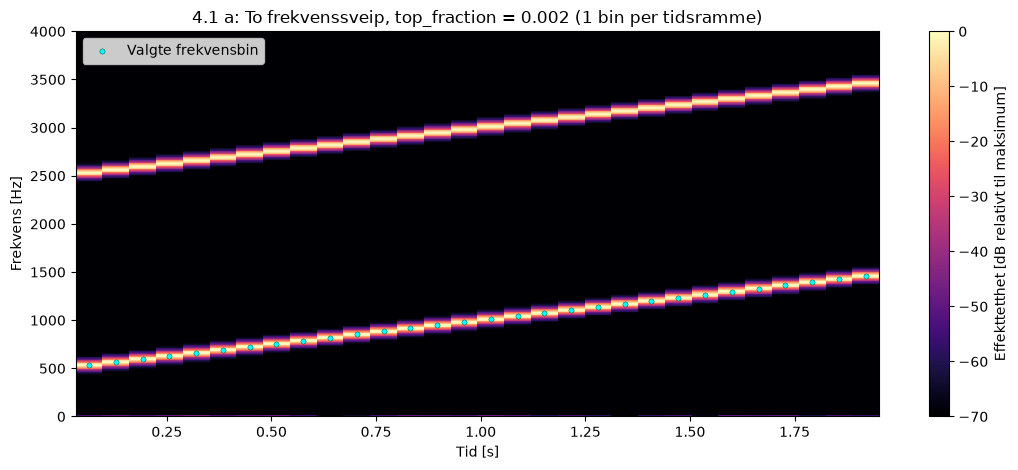

top_fraction = 0.004: 2 bin per ramme, 60 punkter totalt (32 på x1 og 28 på x2)


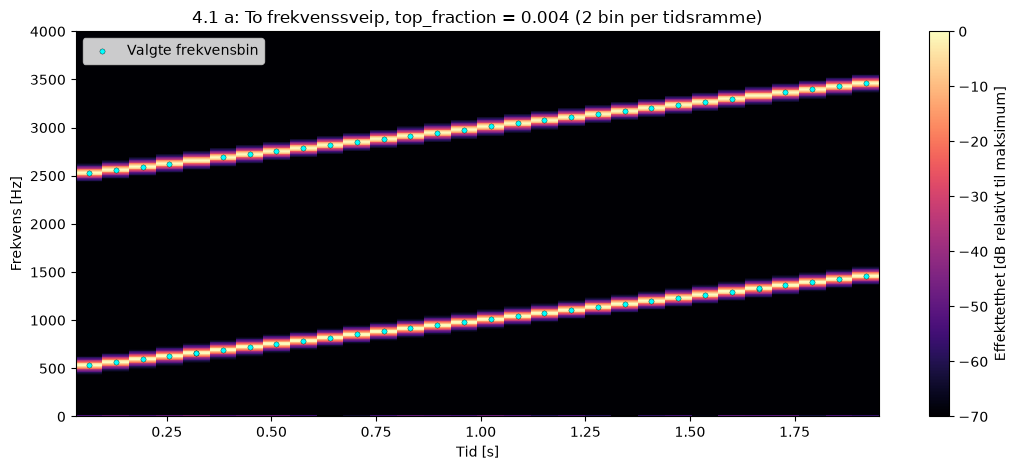

In [5]:
for top_fraction in (0.002, 0.004):
    peak_tt, peak_freqs = pick_peaks(Sxx, tt, f_axis, top_fraction)
    n_keep = int(len(f_axis) * top_fraction)

    # Tell hvor mange punkter som havner på hvert av de to sveipene
    peak_freqs_array = np.asarray(peak_freqs)
    n_x1 = int(np.sum(peak_freqs_array < 2000))
    n_x2 = int(np.sum(peak_freqs_array > 2000))

    print(f"top_fraction = {top_fraction}: {n_keep} bin per ramme, "
          f"{len(peak_tt)} punkter totalt ({n_x1} på x1 og {n_x2} på x2)")
    plot_spectrogram(
        f_axis, tt, Sxx, peak_tt, peak_freqs,
        f"4.1 a: To frekvenssveip, top_fraction = {top_fraction} "
        f"({n_keep} bin per tidsramme)",
    )

* **Hvor mange frekvensbin inneholder spektrogrammet?**

  Det inneholder $L_\text{window}/2 + 1 = 1024/2 + 1 = 513$ frekvensbin fra 0 Hz til $f_s/2 = 4000$ Hz, med avstand $f_s/L_\text{window} = 7{,}8125$ Hz.

* **Hvor mange frekvensbin beholdes per tidsramme?**

  - `top_fraction = 0.002`: $\lfloor 513 \cdot 0{,}002 \rfloor = 1$ bin
  - `top_fraction = 0.004`: $\lfloor 513 \cdot 0{,}004 \rfloor = 2$ bin

* **Hvorfor følger punktene først bare det sterkeste frekvenssveipet?**

  `pick_peaks` rangerer binnene bare etter effekt. Effekten er proporsjonal med $A^2$, så x1 er $1/0{,}99^2 \approx 1{,}02$ ganger sterkere enn x2. Sveipene ligger nøyaktig 2000 Hz = 256 bin fra hverandre og øker like raskt, så de har samme form i spekteret. Med ett bin per ramme velges derfor alltid toppen til x1.

  Med to bin per ramme havner det andre punktet på x2 i 28 av 30 rammer. I de to andre rammene ligger frekvensen til x1 nesten midt mellom to bin. Da er nabobinnet i hovedloben til x1 (Hann-vinduets hovedlobe er 4 bin bred) sterkere enn toppen til x2, og begge punktene havner på x1. Et litt svakere signal blir altså oversett når vi beholder for få bin.

### 4.1 b

Vi velger song_009.wav og bruker hele lydfilen. Spektrogrammet beregnes med
Hann-vindu, vinduslengde 1024 og overlapp 512 sampler. De 0,2 % sterkeste
frekvensbinnene markeres, altså ett bin per tidsramme med dette oppsettet.

Lydfil: song_009.wav
Samplingsfrekvens: 8000 Hz
Varighet: 132.15 s
Frekvensbin: 513
Tidsrammer: 2063
Beholdte bin per ramme: 1
Antall markerte punkter: 2063


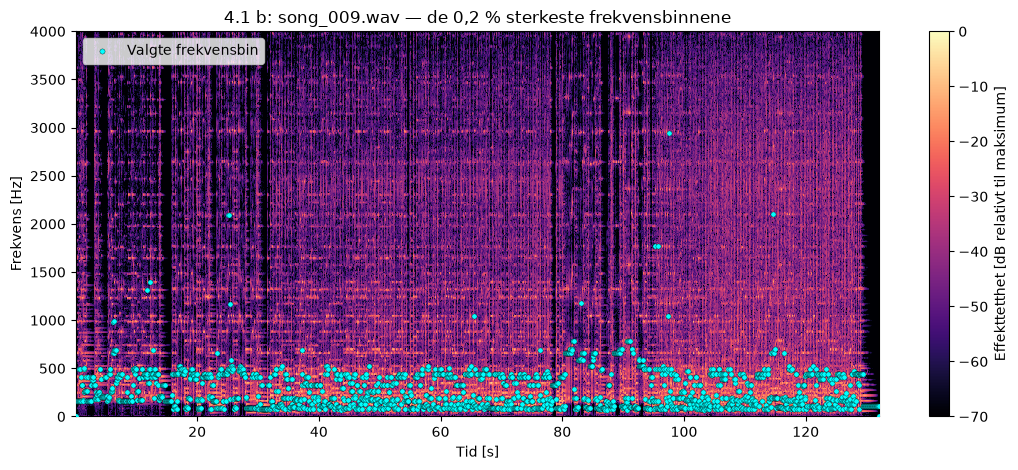

In [6]:
# Last inn den valgte sangen
library_folder = Path("library_wav")
song_path = library_folder / "song_009.wav"
fs_song, x_song = wavfile.read(song_path)

f_song, tt_song, Sxx_song = spectrogram(
    x_song, fs=fs_song, window="hann", nperseg=L_window,
    noverlap=L_overlap, scaling="density",
)
peaks_song = pick_peaks(Sxx_song, tt_song, f_song, top_fraction=0.002)

print(f"Lydfil: {song_path.name}")
print(f"Samplingsfrekvens: {fs_song} Hz")
print(f"Varighet: {len(x_song) / fs_song:.2f} s")
print(f"Frekvensbin: {len(f_song)}")
print(f"Tidsrammer: {len(tt_song)}")
print(f"Beholdte bin per ramme: {int(len(f_song) * 0.002)}")
print(f"Antall markerte punkter: {len(peaks_song[0])}")

plot_spectrogram(
    f_song, tt_song, Sxx_song, *peaks_song,
    title=f"4.1 b: {song_path.name} — de 0,2 % sterkeste frekvensbinnene",
)

**Resultat:** Lydfilen har samplingsfrekvens 8000 Hz og varighet 132,15 s. Spektrogrammet inneholder 513 frekvensbin og 2063 tidsrammer. Med `top_fraction = 0.002` beholdes ett bin per ramme, noe som gir **2063 markerte punkter**. Punktene viser hvilken frekvens som har størst effekttetthet i hver ramme. De følger derfor ikke nødvendigvis sangens melodi, siden for eksempel bass eller en sterk overtone kan dominere. Figuren viser at de fleste punktene ligger under ca. 500 Hz.

## Oppgave 4.2: Konstruere fingeravtrykk

Hver topp $(t_1, f_1)$ brukes som ankerpunkt og kobles til de `fan_out` neste toppene $(t_2, f_2)$ i lista. Hashen er $h = (f_1, f_2, \Delta t)$ med $\Delta t = t_2 - t_1$, og den lagres sammen med $t_1$. Hashen inneholder bare *relativ* tid. Den blir derfor lik uansett hvor i sangen et utsnitt starter, så lenge de samme toppene blir funnet (se 4.5), og det er dette som gjør at et kort utsnitt kan kjennes igjen.

Tidspunktene fra `spectrogram` er flyttall, og differansen $t_2 - t_1$ blir ikke alltid bit-lik for samme antall rammer (se testen under). Hashene brukes som eksakte nøkler i en dictionary, så like tidsforskjeller ville da gitt ulike hasher. Vi runder derfor $\Delta t$ til hele millisekunder. Frekvensene hentes direkte fra den samme frekvensaksen `f` og trenger ikke avrunding.

In [7]:
def build_hashes(peaks, fan_out):
    """
    Lager kjennetegn fra frekvenstoppene
    Args:
    peaks (tuple): Lister med tidspunkter og frekvenser
    fan_out (int): Antall nabotopper som kobles sammen
    Returns:
    hashes (list): Kjennetegn og tilhørende tidspunkt
    """
    hashes = []
    # Pakk ut output fra pick_peaks
    peak_tt, peak_freqs = peaks
    # Loop over alle peaks
    for i in range(len(peak_tt)):
        t1 = peak_tt[i]
        f1 = peak_freqs[i]
        # Koble til nabo-peaks
        for j in range(1, fan_out + 1):
            if i + j >= len(peak_tt):
                break
            t2 = peak_tt[i + j]
            f2 = peak_freqs[i + j]
            # Tidsforskjell, avrundet til ms slik at like dt gir like hasher
            dt = round(t2 - t1, 3)
            # Lag hash
            h = (f1, f2, dt)
            # Lagre hash sammen med tidspunktet til ankerpunktet
            hashes.append((h, t1))
    return hashes

In [8]:
# Flyttallsproblemet: dt mellom nabo-rammer i song_009 uten avrunding
print("dt uten avrunding:", float(tt_song[1] - tt_song[0]),
      float(tt_song[8] - tt_song[7]), float(tt_song[9] - tt_song[8]))

# Test på toppene fra song_009 (4.1 b) med fan_out = 5
hashes_song = build_hashes(peaks_song, fan_out=5)
print(f"Antall topper: {len(peaks_song[0])}")
print(f"Antall hasher: {len(hashes_song)}")
print("Fem hasher med samme ankerpunkt, ((f1 [Hz], f2 [Hz], dt [s]), t1 [s]):")
for h, t1 in hashes_song[5000:5005]:
    print(f"  (({h[0]:.2f}, {h[1]:.2f}, {h[2]:.3f}), {t1:.3f})")

dt uten avrunding: 0.064 0.06399999999999995 0.06400000000000006
Antall topper: 2063
Antall hasher: 10300
Fem hasher med samme ankerpunkt, ((f1 [Hz], f2 [Hz], dt [s]), t1 [s]):
  ((78.12, 164.06, 0.064), 64.064)
  ((78.12, 109.38, 0.128), 64.064)
  ((78.12, 109.38, 0.192), 64.064)
  ((78.12, 437.50, 0.256), 64.064)
  ((78.12, 445.31, 0.320), 64.064)


Uten avrunding får samme tidsforskjell (én ramme, 64 ms) tre ulike flyttallsverdier. Hver av de 2063 toppene kobles til 5 naboer, bortsett fra de fem siste som har færre naboer igjen. Det gir $2063 \cdot 5 - (1+2+3+4+5) = 10\,300$ hasher, som stemmer med utskriften. De fem hashene med samme ankerpunkt viser `fan_out`: ankeret kobles til toppene 1–5 rammer senere, altså $\Delta t = 0{,}064$–$0{,}320$ s.

## Oppgave 4.3: Konstruer database

Databasen er en dictionary der nøkkelen er en hash og verdien er en liste med alle `(song_id, t1)` der hashen forekommer. Alle sangene behandles likt: STFT → `pick_peaks` → `build_hashes` → lagring. `song_id` er nummeret i den sorterte lista fra `load_library`, så `song_id = 1` svarer til `song_001.wav`.

In [9]:
def build_database(songs, L_window, L_overlap, top_fraction, fan_out):
    """
    Lager en database med kjennetegn fra sangene
    Args:
    songs (list): Lyddata og samplingsfrekvens for hver sang
    L_window (int): Størrelsen på hver ramme
    L_overlap (int): Antall overlappende sampler mellom rammer
    top_fraction (float): Andelen frekvenser som beholdes
    fan_out (int): Antall nabotopper som kobles sammen
    Returns:
    database (dict): Kjennetegn med sangnummer og tidspunkt
    """
    database = {}
    # Loop over alle sanger
    for song_id, (fs, x) in enumerate(songs, start=1):
        # STFT
        f, tt, Sxx = spectrogram(
            x, fs=fs, window="hann", nperseg=L_window,
            noverlap=L_overlap, scaling="density",
        )
        # Finn peaks
        peaks = pick_peaks(Sxx, tt, f, top_fraction)
        # Lag hashes
        hashes = build_hashes(peaks, fan_out)
        # Lagre hashes i databasen
        for h, t in hashes:
            if h not in database:
                database[h] = []
            database[h].append((song_id, t))
    return database

### 4.3 a

In [10]:
# Last inn alle sangene fra Library_wav
songs = load_library(library_folder)

L_window = 1024
L_overlap = 512
top_fraction = 0.002
fan_out = 5

database = build_database(songs, L_window, L_overlap, top_fraction, fan_out)
save_database(database, "database.pkl")

# Last inn den lagrede databasen og undersøk innholdet
db = load_database("database.pkl")
n_hashes = len(db)
n_stored_matches = sum(len(song_times) for song_times in db.values())

print(f"Antall sanger: {len(songs)}")
print(f"Antall ulike hasher, n_hashes: {n_hashes}")
print(f"Totalt antall lagrede (song_id, t)-par, n_stored_matches: {n_stored_matches}")

# Hashen som forekommer oftest
h_max, forekomster = max(db.items(), key=lambda item: len(item[1]))
sanger = sorted({song_id for song_id, _ in forekomster})
print(f"Vanligste hash: ({h_max[0]:.2f} Hz, {h_max[1]:.2f} Hz, {h_max[2]} s) med "
      f"{len(forekomster)} forekomster i {len(sanger)} av {len(songs)} sanger")

Antall sanger: 11
Antall ulike hasher, n_hashes: 14769
Totalt antall lagrede (song_id, t)-par, n_stored_matches: 112575
Vanligste hash: (109.38 Hz, 109.38 Hz, 0.064 s) med 936 forekomster i 10 av 11 sanger


Databasen har 14 769 ulike hasher, men 112 575 lagrede `(song_id, t)`-par, altså i snitt omtrent 7,6 forekomster per hash. Mange hasher går altså igjen. Den vanligste har $f_1 = f_2 \approx 109$ Hz og $\Delta t = 64$ ms (én ramme), og finnes i nesten alle sangene. Den kommer fra en vedvarende basstone, der samme bin er sterkest i flere rammer på rad. En slik hash sier lite om hvilken sang det er. Matchingen i 4.4 ser derfor også på tidsforskyvningen, ikke bare på om hashen finnes.

### 4.3 b

Vi bygger databasen på nytt og dobler én parameter om gangen for å se hvordan antall hasher og lagrede par endres.

In [11]:
H = L_window - L_overlap
n_frames = [1 + (len(x) - L_window) // H for fs, x in songs]

print(f"{'top_fraction':>12} {'fan_out':>7} {'n_keep':>6} {'n_hashes':>9} "
      f"{'n_stored':>9} {'formel':>9}")
for tf, fo in [(0.002, 5), (0.004, 5), (0.002, 10)]:  # (top_fraction, fan_out)
    db_test = build_database(songs, L_window, L_overlap, tf, fo)
    n_keep = int((L_window // 2 + 1) * tf)
    n_stored = sum(len(song_times) for song_times in db_test.values())
    n_formel = sum(N * n_keep * fo - fo * (fo + 1) // 2 for N in n_frames)
    print(f"{tf:>12} {fo:>7} {n_keep:>6} {len(db_test):>9} {n_stored:>9} {n_formel:>9}")

top_fraction fan_out n_keep  n_hashes  n_stored    formel


       0.002       5      1     14769    112575    112575


       0.004       5      2     19008    225315    225315


       0.002      10      1     30389    224875    224875


Med $p$ = `top_fraction` og $F$ = `fan_out` gir hver sang $N_\text{rammer} \cdot n_\text{keep}$ topper, der $n_\text{keep} = \lfloor 513\, p \rfloor$. Hver topp kobles til $F$ naboer, bortsett fra de siste toppene i sangen. Antall lagrede par blir derfor

$$
N_\text{lagret} = \sum_\text{sanger} \left( N_\text{rammer}\, n_\text{keep}\, F - \frac{F(F+1)}{2} \right),
$$

og tabellen viser at dette stemmer eksakt.

* **Økt `top_fraction`:** Flere bin beholdes per ramme, så antall topper og lagrede par øker proporsjonalt med $n_\text{keep}$. Fra 0,002 til 0,004 dobles `n_stored`. Fordi $n_\text{keep}$ rundes ned, skjer økningen i trinn. Antall ulike hasher øker derimot bare med ca. 29 %. Det nest sterkeste binnet er nemlig ofte nabobinnet i samme hovedlobe, så mange av de nye hashene blir like. I tillegg teller `fan_out` topper, ikke rammer. Med to topper per ramme dekker `fan_out = 5` bare omtrent 2,5 rammer fremover, og noen hasher får $\Delta t = 0$. Hver hash forekommer derfor oftere (ca. 12 mot 7,6 ganger i snitt) og blir mindre spesifikk for én sang. Svake bin påvirkes dessuten lettere av støy.
* **Økt `fan_out`:** Hver topp gir flere hasher, så antall lagrede par øker lineært med `fan_out` og dobles fra 5 til 10. Her dobles også antall ulike hasher omtrent (ca. 2,1 ganger). De nye hashene har større $\Delta t$ enn de gamle og blir derfor nye kombinasjoner. Flere hasher gir flere stemmer ved matching og dermed mer robust gjenkjenning, men databasen blir større og søket tregere.

Kort sagt blir databasen større (både `n_hashes` og `n_stored_matches` øker) når én av parameterne økes. Valget er en avveining mellom robusthet på den ene siden og lagring og beregningstid på den andre. Økt `fan_out` gir flere hasher som er like spesifikke som før, mens økt `top_fraction` hovedsakelig gir flere forekomster av de samme hashene.

## Oppgave 4.4: Matching-algoritme

Søkesignalet (query) behandles på samme måte som sangene i databasen. For hver hash fra søkesignalet som finnes i databasen, beregnes $\text{offset} = t_\text{database} - t_\text{query}$, og paret `(song_id, offset)` får én stemme.

Hvis utsnittet starter ved tiden $t_0$ i sang $s$, gir alle riktige treff omtrent samme forskyvning, $\text{offset} \approx t_0$. Stemmene samles da på paret $(s, t_0)$. Tilfeldige treff, for eksempel vanlige basstone-hasher fra andre sanger, fordeles på mange ulike forskyvninger, så hver av dem får få stemmer. Sangen med flest stemmer på én og samme forskyvning velges. Forskyvningen rundes til millisekunder av samme grunn som $\Delta t$ i 4.2.

In [12]:
def match_query(x, fs, database, L_window, L_overlap, top_fraction, fan_out):
    """
    Finner sangen som passer best med lydklippet
    Args:
    x (array-like): Signalet som skal gjenkjennes
    fs (int): Antall sampler per sekund
    database (dict): Databasen det skal søkes i
    L_window (int): Størrelsen på hver ramme
    L_overlap (int): Antall overlappende sampler mellom rammer
    top_fraction (float): Andelen frekvenser som beholdes
    fan_out (int): Antall nabotopper som kobles sammen
    Returns:
    best_song (int or None): Sangen med flest treff
    best_score (int): Antall treff
    """
    # Beregn STFT
    f, tt, Sxx = spectrogram(
        x, fs=fs, window="hann", nperseg=L_window,
        noverlap=L_overlap, scaling="density",
    )
    # Finn peaks
    peaks = pick_peaks(Sxx, tt, f, top_fraction)
    # Lag hashes
    hashes = build_hashes(peaks, fan_out)

    votes = {}
    # Loop over hashes
    for h, t_query in hashes:
        if h in database:
            matches = database[h]
            for song_id, t_db in matches:
                # Beregn tidsforskyvning (avrundet til ms)
                offset = round(t_db - t_query, 3)
                key = (song_id, offset)
                if key not in votes:
                    votes[key] = 0
                votes[key] += 1

    # Finn beste match
    best_song = None
    best_score = 0
    for song_id, offset in votes:
        score = votes[(song_id, offset)]
        if score > best_score:
            best_score = score
            best_song = song_id
    return best_song, best_score

## Oppgave 4.5: Testing og resultater

Databasen fra 4.3 a, bygget av de komplette sangene, brukes. Korte utsnitt av sangene brukes som ukjente søkesignal.

### Utsnitt fra én lydfil

In [13]:
fs, audio = wavfile.read("library_wav/song_004.wav")

start_time = 10
duration = 2

query = audio[start_time * fs: (start_time + duration) * fs]

db = load_database("database.pkl")
song_id, score = match_query(query, fs, db, L_window, L_overlap,
                             top_fraction, fan_out)

print("Riktig sang: song_004.wav")
print("song_id:", song_id)
print("score:", score)

Riktig sang: song_004.wav
song_id: 4
score: 68


### Flere sanger og ulike steder i samme sang

Alle de 11 sangene testes med 2 s lange utsnitt som starter ved 20 %, 40 %, 60 % og 80 % av sangens lengde.

In [14]:
def test_query(song_id, start_time, duration):
    """Klipper ut et utsnitt fra en sang og matcher det mot databasen."""
    fs, audio = songs[song_id - 1]
    query = audio[int(start_time * fs): int((start_time + duration) * fs)]
    return match_query(query, fs, db, L_window, L_overlap, top_fraction, fan_out)

andeler = (0.2, 0.4, 0.6, 0.8)
duration = 2
n_riktig = 0

for song_id, (fs, audio) in enumerate(songs, start=1):
    starts, funnet, scores = [], [], []
    for andel in andeler:
        start_time = int(andel * len(audio) / fs)
        starts.append(start_time)
        found, score = test_query(song_id, start_time, duration)
        funnet.append(found)
        scores.append(score)
    n_riktig += funnet.count(song_id)
    print(f"song_{song_id:03d}.wav  start [s]: {starts}  funnet: {funnet}  score: {scores}")

print(f"\nRiktig identifisert: {n_riktig} av {len(songs) * len(andeler)}")

song_001.wav  start [s]: [25, 51, 76, 102]  funnet: [1, 1, 1, 1]  score: [130, 103, 95, 76]
song_002.wav  start [s]: [28, 57, 85, 114]  funnet: [2, 2, 2, 2]  score: [74, 75, 106, 87]


song_003.wav  start [s]: [16, 32, 48, 64]  funnet: [3, 3, 3, 3]  score: [135, 135, 135, 135]
song_004.wav  start [s]: [47, 94, 141, 188]  funnet: [4, 4, 4, 4]  score: [135, 121, 95, 112]


song_005.wav  start [s]: [22, 44, 66, 89]  funnet: [5, 5, 5, 5]  score: [57, 63, 64, 49]


song_006.wav  start [s]: [30, 60, 91, 121]  funnet: [6, 6, 6, 6]  score: [101, 105, 67, 84]


song_007.wav  start [s]: [24, 48, 72, 96]  funnet: [7, 7, 7, 7]  score: [135, 135, 135, 135]
song_008.wav  start [s]: [25, 51, 77, 102]  funnet: [8, 8, 8, 8]  score: [59, 89, 92, 63]


song_009.wav  start [s]: [26, 52, 79, 105]  funnet: [9, 9, 9, 9]  score: [56, 67, 64, 24]
song_010.wav  start [s]: [31, 63, 95, 127]  funnet: [10, 10, 10, 10]  score: [81, 72, 88, 84]


song_011.wav  start [s]: [10, 21, 31, 42]  funnet: [11, 11, 11, 11]  score: [55, 76, 36, 58]

Riktig identifisert: 44 av 44


Alle utsnittene identifiseres riktig, fra alle fire posisjoner i alle sangene. Scoren varierer mellom sanger og posisjoner. Et utsnitt på 2 s gir 30 rammer og dermed $30 \cdot 5 - 15 = 135$ hasher, men bare en del av dem treffer på riktig forskyvning. Hovedårsaken er at rammene i query ikke ligger på samme tidsrutenett som i databasen, fordi startpunktet $t_0 f_s$ sjelden er et helt antall hopp $H = 512$. Spektrene beregnes da fra litt forskjellige segmenter. I rammer der to bin er nesten like sterke, kan et annet bin bli sterkest, og da endres alle hashene som bruker den toppen. Dette bekreftes av song_003 og song_007. Der starter alle utsnittene på et multiplum av 8 s, og $8\,\text{s} \cdot 8000\,\text{Hz} = 64\,000 = 125 \cdot 512$ sampler er et helt antall hopp. Rammene blir da identiske med rammene i databasen, og alle 135 hashene treffer.

### Lengden på søkesignalet

Testen over (11 sanger × 4 posisjoner) gjentas for ulike lengder på utsnittet. Antall hasher i query er en øvre grense for scoren, og den tegnes inn som referanse.

 0.25 s:  9 av 44 riktig, gjennomsnittlig score    1.0, hasher i query    1


  0.5 s: 32 av 44 riktig, gjennomsnittlig score   11.7, hasher i query   15


    1 s: 42 av 44 riktig, gjennomsnittlig score   38.8, hasher i query   55


    2 s: 44 av 44 riktig, gjennomsnittlig score   89.6, hasher i query  135


    4 s: 44 av 44 riktig, gjennomsnittlig score  189.5, hasher i query  290


    8 s: 44 av 44 riktig, gjennomsnittlig score  393.0, hasher i query  605


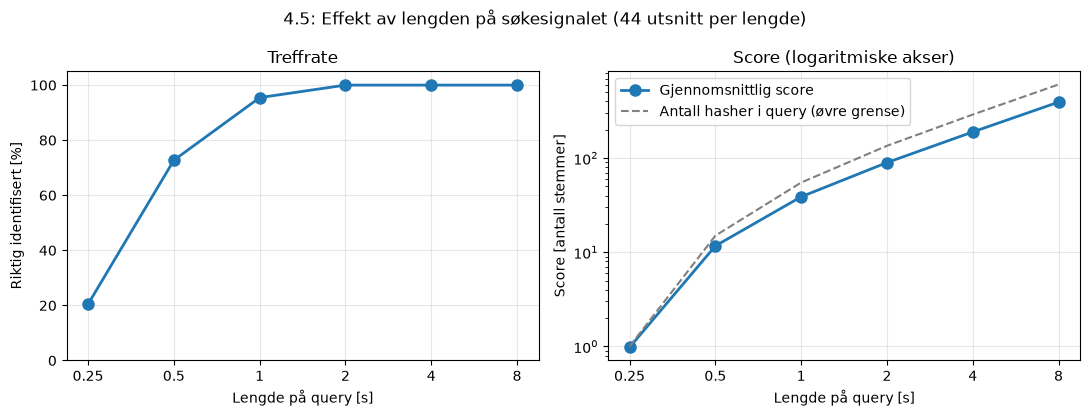

In [15]:
durations = [0.25, 0.5, 1, 2, 4, 8]
n_keep = int((L_window // 2 + 1) * top_fraction)
prosent_riktig, snitt_score, n_query_hashes = [], [], []

for duration in durations:
    riktig, scores = 0, []
    for song_id, (fs, audio) in enumerate(songs, start=1):
        for andel in andeler:
            start_time = int(andel * len(audio) / fs)
            found, score = test_query(song_id, start_time, duration)
            riktig += found == song_id
            scores.append(score)

    # Antall hasher i query: hver topp kobles til opptil fan_out naboer
    n_peaks = (1 + (int(duration * fs) - L_window) // H) * n_keep
    n_query_hashes.append(sum(min(fan_out, n_peaks - 1 - i) for i in range(n_peaks)))
    prosent_riktig.append(100 * riktig / len(scores))
    snitt_score.append(np.mean(scores))
    print(f"{duration:>5} s: {riktig:>2} av {len(scores)} riktig, "
          f"gjennomsnittlig score {snitt_score[-1]:6.1f}, "
          f"hasher i query {n_query_hashes[-1]:>4}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.plot(durations, prosent_riktig, "o-", lw=2, ms=8)
ax1.set_ylabel("Riktig identifisert [%]")
ax1.set_title("Treffrate")
ax1.set_ylim(0, 105)

ax2.plot(durations, snitt_score, "o-", lw=2, ms=8, label="Gjennomsnittlig score")
ax2.plot(durations, n_query_hashes, "--", color="gray", lw=1.5,
         label="Antall hasher i query (øvre grense)")
ax2.set_ylabel("Score [antall stemmer]")
ax2.set_yscale("log")
ax2.set_title("Score (logaritmiske akser)")
ax2.legend(loc="upper left")

for ax in (ax1, ax2):
    ax.set_xscale("log", base=2)
    ax.set_xticks(durations, [f"{d:g}" for d in durations])
    ax.set_xlabel("Lengde på query [s]")
    ax.grid(alpha=0.3)

fig.suptitle("4.5: Effekt av lengden på søkesignalet (44 utsnitt per lengde)")
fig.tight_layout()
plt.show()

* **Kort query gir få hasher.** Med hopp $H/f_s = 64$ ms får vi omtrent 15,6 rammer per sekund, og med ett bin per ramme like mange topper. Et utsnitt på 0,25 s gir bare 2 rammer og 1 hash. Da får alle sanger som inneholder denne hashen score 1, og ved uavgjort beholder `match_query` den første sangen som fikk en stemme, altså den med lavest `song_id`. De 20 % riktige skyldes derfor rekkefølgen ved uavgjort, ikke gjenkjenning. Ved 0,5 s (6 rammer, 15 hasher) er 73 % riktige, ved 1 s er 95 % riktige, og fra 2 s identifiseres alle utsnittene. Dette stemmer med hintet i oppgaven: er query for kort, blir det for få hasher, og andre sanger kan få like mange eller flere stemmer enn riktig sang.
* **Scoren øker omtrent lineært med lengden.** Antall hasher i query øker lineært med antall rammer, og fra ca. 2 s treffer omtrent to tredjedeler av dem riktig forskyvning. I høyre figur, med logaritmiske akser, er kurvene der omtrent rette og parallelle, altså vokser score og antall hasher proporsjonalt med lengden. For de korteste utsnittene bøyer kurvene av. De første $L_\text{window}$ samplene gir bare én ramme, og de siste toppene har færre enn `fan_out` naboer (leddet $-F(F+1)/2$ i 4.3 b). Tilfeldige treff fordeles på mange forskyvninger, så de vokser ikke på samme måte. Jo lengre utsnittet er, desto tydeligere skiller riktig sang seg ut.
* **Avveininger.** For korte utsnitt kan treffraten økes ved å øke `top_fraction`, som gir flere topper per ramme. Økt `fan_out` hjelper først når query har flere enn `fan_out` + 1 = 6 topper, altså fra litt over 0,5 s. I kortere utsnitt er alle par av topper allerede koblet, for eksempel alle $6 \cdot 5/2 = 15$ par ved 0,5 s. Kostnaden er en større database og flere tilfeldige treff (jf. 4.3 b). Hopplengden $H = L_\text{window} - L_\text{overlap}$ bestemmer antall rammer per sekund ($f_s/H$). Med 50 % overlapp gir et kortere vindu bedre tidsoppløsning og flere rammer, men dårligere frekvensoppløsning ($\Delta f = f_s / L_\text{window}$). Dette er kompromisset mellom tids- og frekvensoppløsning i STFT (avsnitt 2.4 i oppgaven).

## Konklusjon

Vi har laget en forenklet Shazam-algoritme. STFT gir et spektrogram, de sterkeste frekvensbinnene i hver ramme brukes som topper, og par av topper blir hasher $(f_1, f_2, \Delta t)$ som lagres i en database. Hashene inneholder bare relativ tid, og matchingen stemmer på par av sang og tidsforskyvning. Derfor kan et kort utsnitt kjennes igjen uansett hvor i sangen det er hentet fra. Med `L_window = 1024`, `L_overlap = 512`, `top_fraction = 0.002` og `fan_out = 5` ble alle utsnitt på 2 s eller mer identifisert riktig. Svært korte utsnitt (0,5 s eller kortere) ga for få hasher til sikker gjenkjenning. Valg av parametere er en avveining mellom robusthet og størrelsen på databasen.

## Kilder

Anthropic. (2026). *Claude* (Opus 5.5) Brukt som hjelpemiddel til å løse oppgaver. https://claude.ai

GitHub. (2026). *GitHub Copilot* Brukt for autocomplete i editoren. https://github.com/features/copilot